# 11 — Independent state/control state-space model

This notebook builds and evaluates a new linear state-space model from the corrected timestamp dataset. It is self-contained: the model definitions, leave-one-jump-out cross-validation (LOOCV), metrics, baselines, timestamp sensitivity analysis, production fit, exports, and plots are all included here.

The physically preferred formulation is designated after an exploratory comparison, so its LOOCV result should be treated as exploratory rather than as an untouched confirmatory estimate:

- **State** $\mathbf{x}_t$, 7 dimensions: position, coordinate-derived velocity, and measured resultant speed $[x,y,z,v_x,v_y,v_z,s]$. Speed is subsequently predicted recursively.
- **Control** $\mathbf{u}_t$, 19 dimensions: 12 zone-averaged wind variables and 7 measured posture angles.
- **No overlap:** no feature appears in both vectors.
- **Measured resultant speed is excluded from controls:** it is initialized once as a state and is not supplied from the held-out jump at every later step.

Earlier work already contained related ideas: notebook 5 used six kinematic states with 12 wind controls, and an early section of notebook 7 used 14 states with 12 wind controls. Both are reconstructed below as explicit comparison variants using the corrected dataset and the final evaluation procedure.

This remains a **conditional reconstruction** because the full measured posture sequence of each held-out jump is supplied during simulation. Vector independence does not make the model causal or a pre-takeoff forecast.


In [1]:
from __future__ import annotations

import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from sklearn.linear_model import Ridge

ALPHA = 10.0
SAMPLE_INTERVAL_SECONDS = 0.05
RESAMPLED_PATH_POINTS = 1000


def find_project_root() -> Path:
    """Locate the repository whether the notebook starts in root or simulation/."""
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        if (candidate / "simulation").is_dir() and (candidate / "main.tex").exists():
            return candidate
    raise FileNotFoundError("Could not locate the project root")


ROOT = find_project_root()
SIMULATION_DIR = ROOT / "simulation"
DATA_DIR = (
    SIMULATION_DIR
    / "2024_03_Planica_12_winds"
    / "cleaned"
    / "normalized_corrected"
)
DATA_PATH = DATA_DIR / "combined_dataset.npz"
AUDIT_PATH = DATA_DIR / "timestamp_repair_audit.csv"

OUTPUT_METRICS = SIMULATION_DIR / "independent_model_metrics.json"
OUTPUT_PER_JUMP = SIMULATION_DIR / "independent_model_per_jump_metrics.csv"
OUTPUT_COMPARISON = SIMULATION_DIR / "independent_model_comparison.csv"
OUTPUT_FIGURE = ROOT / "independent_model_trajectory_examples.pdf"
MATRIX_OUTPUTS = {
    name: SIMULATION_DIR / f"independent_model_{name}.csv"
    for name in "ABCD"
}

print(f"Project root: {ROOT}")
print(f"Corrected dataset: {DATA_PATH}")


Project root: C:\Users\vsi\Desktop\ijs\smucarski_skoki\project
Corrected dataset: C:\Users\vsi\Desktop\ijs\smucarski_skoki\project\simulation\2024_03_Planica_12_winds\cleaned\normalized_corrected\combined_dataset.npz


In [2]:
# Load the corrected 203-jump archive created by rebuild_dataset.py.
archive = np.load(DATA_PATH, allow_pickle=True)
full_states = [np.asarray(value, dtype=float) for value in archive["X"]]
observations = [np.asarray(value, dtype=float) for value in archive["Y"]]
full_controls = [np.asarray(value, dtype=float) for value in archive["U"]]
filenames = [str(value) for value in archive["filenames"]]

if not (
    len(full_states)
    == len(observations)
    == len(full_controls)
    == len(filenames)
    == 203
):
    raise ValueError("Expected 203 aligned accepted jumps")

KINEMATIC_STATE_NAMES = ["x", "y", "z", "vx", "vy", "vz"]
POSTURE_NAMES = [
    "opening_angle",
    "roll_left",
    "roll_right",
    "yaw_left",
    "yaw_right",
    "stall_left",
    "stall_right",
]
KINEMATIC_SPEED_STATE_NAMES = [*KINEMATIC_STATE_NAMES, "resulting_speed"]
FULL_STATE_NAMES = [
    *KINEMATIC_STATE_NAMES,
    "resulting_speed",
    *POSTURE_NAMES,
]
WIND_NAMES = [
    f"{component}_{zone}"
    for component in ("wind_speed", "wind_tangent", "crosswind", "turbulence")
    for zone in ("takeoff", "middle", "landing")
]
CURRENT_CONTROL_NAMES = [*WIND_NAMES, "resulting_speed", *POSTURE_NAMES]

kinematic_states = [state[:, :6] for state in full_states]
kinematic_speed_states = [state[:, :7] for state in full_states]
primary_controls = [
    np.column_stack((control[:, :12], control[:, 13:20]))
    for control in full_controls
]
wind_controls = [control[:, :12] for control in full_controls]

variants = {
    # Primary scientific formulation: kinematic state; wind + posture controls.
    "kinematic_wind_posture": {
        "states": kinematic_states,
        "controls": primary_controls,
        "state_names": KINEMATIC_STATE_NAMES,
        "control_names": [*WIND_NAMES, *POSTURE_NAMES],
        "role": "ablation_no_speed",
    },
    # Physical candidate: speed is predicted as a state, never supplied as a control.
    "kinematic_speed_state_wind_posture": {
        "states": kinematic_speed_states,
        "controls": primary_controls,
        "state_names": KINEMATIC_SPEED_STATE_NAMES,
        "control_names": [*WIND_NAMES, *POSTURE_NAMES],
        "role": "primary",
    },
    # Diagnostic: tests the benefit of supplying measured speed as another input.
    "kinematic_wind_speed_posture": {
        "states": kinematic_states,
        "controls": full_controls,
        "state_names": KINEMATIC_STATE_NAMES,
        "control_names": CURRENT_CONTROL_NAMES,
        "role": "diagnostic",
    },
    # Reconstructs the independent formulation found in notebook 5.
    "kinematic_wind_only": {
        "states": kinematic_states,
        "controls": wind_controls,
        "state_names": KINEMATIC_STATE_NAMES,
        "control_names": WIND_NAMES,
        "role": "notebook_5_variant",
    },
    # Reconstructs the independent formulation found early in notebook 7.
    "full_state_wind_only": {
        "states": full_states,
        "controls": wind_controls,
        "state_names": FULL_STATE_NAMES,
        "control_names": WIND_NAMES,
        "role": "notebook_7_variant",
    },
}

for name, specification in variants.items():
    state_names = specification["state_names"]
    control_names = specification["control_names"]
    overlap = set(state_names).intersection(control_names)
    if overlap:
        raise AssertionError(f"{name} has state/control overlap: {sorted(overlap)}")
    for state, control in zip(
        specification["states"], specification["controls"], strict=True
    ):
        if len(state) != len(control):
            raise AssertionError(f"{name} has a state/control length mismatch")

variant_definitions = pd.DataFrame(
    [
        {
            "variant": name,
            "role": specification["role"],
            "state_dimension": len(specification["state_names"]),
            "control_dimension": len(specification["control_names"]),
            "overlap_count": len(
                set(specification["state_names"]).intersection(
                    specification["control_names"]
                )
            ),
        }
        for name, specification in variants.items()
    ]
)
display(variant_definitions)


,variant,role,state_dimension,control_dimension,overlap_count
0,kinematic_wind_posture,ablation_no_speed,6,19,0
1,kinematic_speed_state_wind_posture,primary,7,19,0
2,kinematic_wind_speed_posture,diagnostic,6,20,0
3,kinematic_wind_only,notebook_5_variant,6,12,0
4,full_state_wind_only,notebook_7_variant,14,12,0


## Evaluation functions

The following cells reproduce the final article evaluation rather than using the older notebook metrics. Every Ridge model is fitted with $\alpha=10$, no intercept, and no feature standardization so the comparison with the current 14-state/20-control model is direct.

LOOCV is grouped by complete jump. For every held-out jump, both the transition matrices and the training-mean initial state are estimated from the other 202 jumps. The average-path baseline is also reconstructed from training jumps only.


In [3]:
def merge_duplicate_x(points: np.ndarray) -> np.ndarray:
    """Sort a 3-D path by x and average y/z at duplicate x values."""
    order = np.argsort(points[:, 0], kind="stable")
    points = np.asarray(points, dtype=float)[order]
    unique_x, inverse = np.unique(points[:, 0], return_inverse=True)
    merged = np.zeros((len(unique_x), 3), dtype=float)
    counts = np.bincount(inverse)
    merged[:, 0] = unique_x
    merged[:, 1] = np.bincount(inverse, weights=points[:, 1]) / counts
    merged[:, 2] = np.bincount(inverse, weights=points[:, 2]) / counts
    return merged


def interpolate_path_at_x(points: np.ndarray, x_values: np.ndarray) -> np.ndarray:
    points = merge_duplicate_x(points)
    return np.column_stack(
        (
            x_values,
            np.interp(x_values, points[:, 0], points[:, 1]),
            np.interp(x_values, points[:, 0], points[:, 2]),
        )
    )


def trajectory_error(actual: np.ndarray, predicted: np.ndarray) -> float:
    """Mean spatial separation using the article's longitudinal alignment."""
    actual_raw = np.asarray(actual, dtype=float)[:, :3]
    predicted_raw = np.asarray(predicted, dtype=float)[:, :3]
    actual = merge_duplicate_x(actual_raw)
    predicted = merge_duplicate_x(predicted_raw)
    distances = [float(np.linalg.norm(actual_raw[0] - predicted_raw[0]))]

    actual_integer_x = np.arange(
        math.ceil(actual[0, 0]), math.floor(actual[-1, 0]) + 1
    )
    predicted_integer_x = np.arange(
        math.ceil(predicted[0, 0]), math.floor(predicted[-1, 0]) + 1
    )
    common_x = np.intersect1d(actual_integer_x, predicted_integer_x)
    common_x = common_x[
        common_x > max(actual_raw[0, 0], predicted_raw[0, 0])
    ]
    if len(common_x):
        actual_common = interpolate_path_at_x(actual, common_x)
        predicted_common = interpolate_path_at_x(predicted, common_x)
        distances.extend(np.linalg.norm(actual_common - predicted_common, axis=1))

    if actual[-1, 0] < predicted[-1, 0]:
        tail_x = np.arange(
            math.floor(actual[-1, 0]) + 1,
            math.floor(predicted[-1, 0]) + 1,
        )
        if len(tail_x):
            predicted_tail = interpolate_path_at_x(predicted, tail_x)
            distances.extend(np.linalg.norm(predicted_tail - actual[-1], axis=1))
        distances.append(float(np.linalg.norm(predicted[-1] - actual[-1])))
    elif actual[-1, 0] > predicted[-1, 0]:
        tail_x = np.arange(
            math.floor(predicted[-1, 0]) + 1,
            math.floor(actual[-1, 0]) + 1,
        )
        if len(tail_x):
            actual_tail = interpolate_path_at_x(actual, tail_x)
            distances.extend(np.linalg.norm(actual_tail - predicted[-1], axis=1))
        distances.append(float(np.linalg.norm(actual[-1] - predicted[-1])))

    return float(np.mean(distances))


def normalized_resample(path: np.ndarray, n_points: int) -> np.ndarray:
    old_progress = np.linspace(0.0, 1.0, len(path))
    new_progress = np.linspace(0.0, 1.0, n_points)
    return np.column_stack(
        [
            np.interp(new_progress, old_progress, path[:, axis])
            for axis in range(3)
        ]
    )


def fit_state_model(
    states: list[np.ndarray],
    controls: list[np.ndarray],
) -> tuple[np.ndarray, np.ndarray]:
    """Fit x[t+1] = A x[t] + B u[t] with dynamic dimensions."""
    x_now = np.vstack([state[:-1] for state in states])
    x_next = np.vstack([state[1:] for state in states])
    u_now = np.vstack([control[:-1] for control in controls])
    regression = Ridge(alpha=ALPHA, fit_intercept=False)
    regression.fit(np.hstack((x_now, u_now)), x_next)
    state_dimension = states[0].shape[1]
    coefficients = regression.coef_
    return (
        coefficients[:, :state_dimension],
        coefficients[:, state_dimension:],
    )


def simulate(
    a: np.ndarray,
    b: np.ndarray,
    initial: np.ndarray,
    controls: np.ndarray,
) -> np.ndarray:
    predicted = np.empty((len(controls), len(initial)), dtype=float)
    predicted[0] = initial
    for index in range(len(controls) - 1):
        predicted[index + 1] = a @ predicted[index] + b @ controls[index]
    if not np.isfinite(predicted).all():
        raise FloatingPointError("Simulation produced a non-finite value")
    return predicted


def landing_distance(path: np.ndarray) -> float:
    return float(np.hypot(path[-1, 0], path[-1, 2]))


def interval_95(values: list[float] | np.ndarray) -> tuple[float, float]:
    array = np.asarray(values, dtype=float)
    half_width = stats.t.ppf(0.975, len(array) - 1) * stats.sem(array)
    return (
        float(np.mean(array) - half_width),
        float(np.mean(array) + half_width),
    )


def summarize(values: list[float] | np.ndarray) -> dict[str, object]:
    array = np.asarray(values, dtype=float)
    return {
        "mean": float(np.mean(array)),
        "median": float(np.median(array)),
        "sample_std": float(np.std(array, ddof=1)),
        "ci95_t": list(interval_95(array)),
        "min": float(np.min(array)),
        "max": float(np.max(array)),
    }


In [4]:
def evaluate_variant(
    states: list[np.ndarray],
    controls: list[np.ndarray],
    names: list[str],
) -> tuple[list[dict[str, object]], list[np.ndarray]]:
    """Run jump-level LOOCV and every metric used for the current article model."""
    jump_count = len(states)
    paths_1000 = np.stack(
        [
            normalized_resample(state[:, :3], RESAMPLED_PATH_POINTS)
            for state in states
        ]
    )
    path_sum = np.sum(paths_1000, axis=0)

    records: list[dict[str, object]] = []
    predictions: list[np.ndarray] = []
    for held_out in range(jump_count):
        training_ids = [
            index for index in range(jump_count) if index != held_out
        ]
        training_states = [states[index] for index in training_ids]
        training_controls = [controls[index] for index in training_ids]
        a, b = fit_state_model(training_states, training_controls)

        actual = states[held_out]
        held_out_controls = controls[held_out]
        prediction = simulate(a, b, actual[0], held_out_controls)
        mean_initial = np.mean(
            [state[0] for state in training_states], axis=0
        )
        mean_start_prediction = simulate(
            a, b, mean_initial, held_out_controls
        )

        elapsed = (
            np.arange(len(actual))[:, None] * SAMPLE_INTERVAL_SECONDS
        )
        constant_velocity = (
            actual[0, :3] + elapsed * actual[0, 3:6]
        )

        fold_average_1000 = (
            path_sum - paths_1000[held_out]
        ) / (jump_count - 1)
        fold_mean_length = int(
            round(
                np.mean(
                    [len(states[index]) for index in training_ids]
                )
            )
        )
        average_path = normalized_resample(
            fold_average_1000, fold_mean_length
        )

        records.append(
            {
                "jump_index": held_out,
                "filename": names[held_out],
                "samples": len(actual),
                "duration_seconds": (
                    len(actual) - 1
                ) * SAMPLE_INTERVAL_SECONDS,
                "trajectory_error_actual_start_m": trajectory_error(
                    actual[:, :3], prediction[:, :3]
                ),
                "trajectory_error_training_mean_start_m": trajectory_error(
                    actual[:, :3], mean_start_prediction[:, :3]
                ),
                "trajectory_error_constant_velocity_m": trajectory_error(
                    actual[:, :3], constant_velocity
                ),
                "trajectory_error_training_average_path_m": trajectory_error(
                    actual[:, :3], average_path
                ),
                "endpoint_error_actual_start_m": float(
                    np.linalg.norm(
                        actual[-1, :3] - prediction[-1, :3]
                    )
                ),
                "landing_distance_absolute_error_actual_start_m": abs(
                    landing_distance(actual[:, :3])
                    - landing_distance(prediction[:, :3])
                ),
                "spectral_radius": float(
                    np.max(np.abs(np.linalg.eigvals(a)))
                ),
            }
        )
        predictions.append(prediction)

    return records, predictions


def summarize_records(
    records: list[dict[str, object]],
) -> dict[str, dict[str, object]]:
    excluded = {"jump_index", "filename", "samples", "duration_seconds"}
    metric_names = [name for name in records[0] if name not in excluded]
    return {
        name: summarize([float(record[name]) for record in records])
        for name in metric_names
    }


## LOOCV comparison of independent formulations

All five variants below have disjoint state and control feature names. The 7-state/19-control model is designated as the physically preferred formulation because it predicts speed recursively instead of supplying measured speed as a control. Because this designation follows exploratory comparison of the variants, its LOOCV score is not an independent confirmatory estimate.


In [5]:
variant_records: dict[str, list[dict[str, object]]] = {}
variant_predictions: dict[str, list[np.ndarray]] = {}
comparison_rows: list[dict[str, object]] = []

comparison_start = time.perf_counter()
for name, specification in variants.items():
    started = time.perf_counter()
    print(f"Evaluating {name} ...")
    records, predictions = evaluate_variant(
        specification["states"],
        specification["controls"],
        filenames,
    )
    variant_records[name] = records
    variant_predictions[name] = predictions
    summary = summarize_records(records)
    comparison_rows.append(
        {
            "variant": name,
            "role": specification["role"],
            "state_dimension": len(specification["state_names"]),
            "control_dimension": len(specification["control_names"]),
            "state_control_overlap": 0,
            "trajectory_mean_m": summary[
                "trajectory_error_actual_start_m"
            ]["mean"],
            "trajectory_median_m": summary[
                "trajectory_error_actual_start_m"
            ]["median"],
            "mean_start_trajectory_mean_m": summary[
                "trajectory_error_training_mean_start_m"
            ]["mean"],
            "endpoint_mean_m": summary[
                "endpoint_error_actual_start_m"
            ]["mean"],
            "terminal_distance_mae_m": summary[
                "landing_distance_absolute_error_actual_start_m"
            ]["mean"],
            "spectral_radius_mean": summary["spectral_radius"]["mean"],
            "elapsed_seconds": time.perf_counter() - started,
        }
    )

comparison = pd.DataFrame(comparison_rows).sort_values("trajectory_mean_m")
comparison.to_csv(OUTPUT_COMPARISON, index=False)
print(
    f"Finished {len(variants)} LOOCV evaluations in "
    f"{time.perf_counter() - comparison_start:.1f} s"
)
display(comparison)


Evaluating kinematic_wind_posture ...


Evaluating kinematic_speed_state_wind_posture ...


Evaluating kinematic_wind_speed_posture ...


Evaluating kinematic_wind_only ...


Evaluating full_state_wind_only ...


Finished 5 LOOCV evaluations in 22.3 s


,variant,role,state_dimension,control_dimension,state_control_overlap,trajectory_mean_m,trajectory_median_m,mean_start_trajectory_mean_m,endpoint_mean_m,terminal_distance_mae_m,spectral_radius_mean,elapsed_seconds
2,kinematic_wind_speed_posture,diagnostic,6,20,0,1.340463,1.185581,1.346122,3.551958,1.662731,1.013571,4.478820
1,kinematic_speed_state_wind_posture,primary,7,19,0,1.349872,1.206691,1.393075,5.727278,4.523205,1.013565,4.850920
4,full_state_wind_only,notebook_7_variant,14,12,0,1.871644,1.691029,1.902917,7.609745,5.537904,1.012734,4.873718
0,kinematic_wind_posture,ablation_no_speed,6,19,0,6.807720,4.840767,6.480821,33.931599,33.349729,1.013640,4.620626
3,kinematic_wind_only,notebook_5_variant,6,12,0,8.161060,5.709567,7.725447,40.004988,39.183693,1.014537,3.441763


## Primary model: full evaluation, timestamp sensitivity, and production matrices

The primary model is **kinematic_speed_state_wind_posture**. Its complete summary contains the same held-out metrics and two baselines used for the current article model. A second LOOCV analysis is restricted to accepted jumps whose timestamps needed no repair.

After evaluation, one production model is fitted to all 203 jumps. The observation equation predicts $[x,y,z,\text{height above ground}]$ from the current state and control:
\[
\mathbf{y}_t=C\mathbf{x}_t+D\mathbf{u}_t.
\]


In [6]:
PRIMARY_NAME = "kinematic_speed_state_wind_posture"
primary_specification = variants[PRIMARY_NAME]
primary_states = primary_specification["states"]
primary_controls_for_model = primary_specification["controls"]
primary_records = variant_records[PRIMARY_NAME]
primary_predictions = variant_predictions[PRIMARY_NAME]
primary_summary = summarize_records(primary_records)

# Sensitivity analysis using only jumps whose timestamps were unchanged.
audit = pd.read_csv(AUDIT_PATH).set_index("filename")
untouched_indices = [
    index
    for index, filename in enumerate(filenames)
    if int(audit.loc[filename, "timestamps_repaired"]) == 0
]
untouched_states = [primary_states[index] for index in untouched_indices]
untouched_controls = [
    primary_controls_for_model[index] for index in untouched_indices
]
untouched_names = [filenames[index] for index in untouched_indices]
untouched_records, _ = evaluate_variant(
    untouched_states, untouched_controls, untouched_names
)
untouched_summary = summarize_records(untouched_records)

print(f"No-timestamp-repair sensitivity jumps: {len(untouched_indices)}")
print(
    "No-repair mean trajectory error: "
    f"{untouched_summary['trajectory_error_actual_start_m']['mean']:.3f} m"
)


No-timestamp-repair sensitivity jumps: 144
No-repair mean trajectory error: 1.422 m


In [7]:
def fit_production_model(
    states: list[np.ndarray],
    controls: list[np.ndarray],
    outputs: list[np.ndarray],
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, dict[str, object]]:
    x_now = np.vstack([state[:-1] for state in states])
    x_next = np.vstack([state[1:] for state in states])
    u_now = np.vstack([control[:-1] for control in controls])
    y_now = np.vstack([output[:-1] for output in outputs])
    predictors = np.hstack((x_now, u_now))
    state_dimension = states[0].shape[1]

    state_regression = Ridge(alpha=ALPHA, fit_intercept=False)
    state_regression.fit(predictors, x_next)
    state_coefficients = state_regression.coef_
    a = state_coefficients[:, :state_dimension]
    b = state_coefficients[:, state_dimension:]

    observation_regression = Ridge(alpha=ALPHA, fit_intercept=False)
    observation_regression.fit(predictors, y_now)
    observation_coefficients = observation_regression.coef_
    c = observation_coefficients[:, :state_dimension]
    d = observation_coefficients[:, state_dimension:]

    predicted_next = x_now @ a.T + u_now @ b.T
    diagnostics = {
        "transitions": int(len(x_now)),
        "spectral_radius_A": float(
            np.max(np.abs(np.linalg.eigvals(a)))
        ),
        "rank_A": int(np.linalg.matrix_rank(a)),
        "rank_B": int(np.linalg.matrix_rank(b)),
        "rank_C": int(np.linalg.matrix_rank(c)),
        "one_step_all_state_rmse": float(
            np.sqrt(np.mean((x_next - predicted_next) ** 2))
        ),
        "one_step_position_rmse_m": float(
            np.sqrt(
                np.mean(
                    (
                        x_next[:, :3]
                        - predicted_next[:, :3]
                    )
                    ** 2
                )
            )
        ),
    }
    return a, b, c, d, diagnostics


A, B, C, D, production_diagnostics = fit_production_model(
    primary_states,
    primary_controls_for_model,
    observations,
)
expected_shapes = ((7, 7), (7, 19), (4, 7), (4, 19))
actual_shapes = (A.shape, B.shape, C.shape, D.shape)
if actual_shapes != expected_shapes:
    raise AssertionError(
        f"Unexpected production matrix shapes: {actual_shapes}"
    )

for name, matrix in zip("ABCD", (A, B, C, D), strict=True):
    np.savetxt(MATRIX_OUTPUTS[name], matrix, delimiter=",")

production_diagnostics


{'transitions': 27531,
 'spectral_radius_A': 1.0135659262944514,
 'rank_A': 7,
 'rank_B': 7,
 'rank_C': 4,
 'one_step_all_state_rmse': 0.5093840500507248,
 'one_step_position_rmse_m': 0.031921684842343034}

In [8]:
# Assemble and save reproducible results.
lengths = np.asarray([len(state) for state in primary_states])
durations = (lengths - 1) * SAMPLE_INTERVAL_SECONDS

metrics = {
    **primary_summary,
    "model": {
        "name": PRIMARY_NAME,
        "description": (
            "Independent 7-state/19-control conditional reconstruction model"
        ),
        "state_names": primary_specification["state_names"],
        "control_names": primary_specification["control_names"],
        "state_dimension": len(primary_specification["state_names"]),
        "control_dimension": len(primary_specification["control_names"]),
        "state_control_overlap": [],
        "ridge_alpha": ALPHA,
        "fit_intercept": False,
        "feature_standardization": False,
    },
    "dataset": {
        "accepted_jumps": len(primary_states),
        "samples_min": int(lengths.min()),
        "samples_median": float(np.median(lengths)),
        "samples_mean": float(lengths.mean()),
        "samples_max": int(lengths.max()),
        "duration_seconds_min": float(durations.min()),
        "duration_seconds_median": float(np.median(durations)),
        "duration_seconds_mean": float(durations.mean()),
        "duration_seconds_max": float(durations.max()),
        "sample_interval_seconds": SAMPLE_INTERVAL_SECONDS,
        "source_archive": str(DATA_PATH.relative_to(ROOT)).replace("\\", "/"),
    },
    "timestamp_sensitivity_no_repair": {
        "jumps": len(untouched_indices),
        "trajectory_error_actual_start_m": untouched_summary[
            "trajectory_error_actual_start_m"
        ],
    },
    "production_fit": {
        **production_diagnostics,
        "matrix_shapes": {
            "A": list(A.shape),
            "B": list(B.shape),
            "C": list(C.shape),
            "D": list(D.shape),
        },
    },
    "candidate_comparison": comparison.to_dict(orient="records"),
}

OUTPUT_METRICS.write_text(
    json.dumps(metrics, indent=2) + "\n", encoding="utf-8"
)
pd.DataFrame(primary_records).to_csv(OUTPUT_PER_JUMP, index=False)

print(f"Wrote {OUTPUT_METRICS.relative_to(ROOT)}")
print(f"Wrote {OUTPUT_PER_JUMP.relative_to(ROOT)}")
print(f"Wrote {OUTPUT_COMPARISON.relative_to(ROOT)}")
for name, path in MATRIX_OUTPUTS.items():
    print(f"Wrote {path.relative_to(ROOT)} with matrix {name}")


Wrote simulation\independent_model_metrics.json
Wrote simulation\independent_model_per_jump_metrics.csv
Wrote simulation\independent_model_comparison.csv
Wrote simulation\independent_model_A.csv with matrix A
Wrote simulation\independent_model_B.csv with matrix B
Wrote simulation\independent_model_C.csv with matrix C
Wrote simulation\independent_model_D.csv with matrix D


,model,state/control dimensions,state/control overlap,trajectory mean (m),trajectory median (m),endpoint mean (m),terminal-distance MAE (m),spectral-radius mean
0,current article model,14 / 20,8,1.339461,1.183705,3.554996,1.684170,1.013495
1,new independent primary,7 / 19,0,1.349872,1.206691,5.727278,4.523205,1.013565


,metric,mean_new_minus_current,ci95_low,ci95_high,fraction_new_lower
0,trajectory_error_actual_start_m,0.010412,-0.028807,0.049630,0.482759
1,trajectory_error_training_mean_start_m,0.047837,0.008348,0.087326,0.497537
2,endpoint_error_actual_start_m,2.172282,1.775062,2.569502,0.197044
3,landing_distance_absolute_error_actual_start_m,2.839036,2.380203,3.297869,0.197044


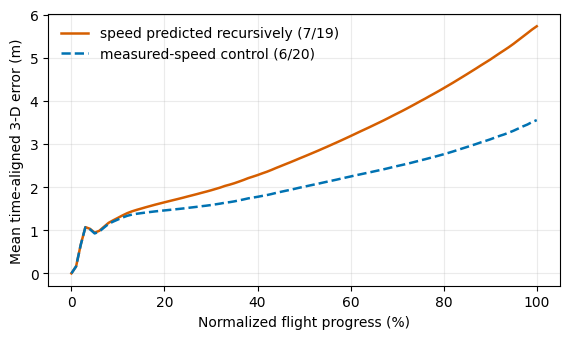

,independent_recursive_speed,measured_speed_control
25,1.782896,1.517546
50,2.707549,2.008176
75,3.991698,2.617831
100,5.727278,3.551958


,r,p_value
speed_mae_vs_terminal_distance_absolute_error,0.797786,4.807870e-46
terminal_speed_error_vs_terminal_distance_signed_error,0.586359,3.878637e-20
duration_vs_terminal_distance_absolute_error,0.015545,8.257737e-01
duration_vs_trajectory_error,0.308533,7.516259e-06


Wrote simulation\independent_model_diagnostics.csv
Wrote simulation\independent_model_error_progression.csv


In [9]:
# Compare the new primary model with the corrected current article model.
current_metrics_path = SIMULATION_DIR / "revision_metrics.json"
current_metrics = json.loads(current_metrics_path.read_text(encoding="utf-8"))

model_comparison = pd.DataFrame(
    [
        {
            "model": "current article model",
            "state/control dimensions": "14 / 20",
            "state/control overlap": 8,
            "trajectory mean (m)": current_metrics[
                "trajectory_error_actual_start_m"
            ]["mean"],
            "trajectory median (m)": current_metrics[
                "trajectory_error_actual_start_m"
            ]["median"],
            "endpoint mean (m)": current_metrics[
                "endpoint_error_actual_start_m"
            ]["mean"],
            "terminal-distance MAE (m)": current_metrics[
                "landing_distance_absolute_error_actual_start_m"
            ]["mean"],
            "spectral-radius mean": current_metrics[
                "spectral_radius"
            ]["mean"],
        },
        {
            "model": "new independent primary",
            "state/control dimensions": "7 / 19",
            "state/control overlap": 0,
            "trajectory mean (m)": primary_summary[
                "trajectory_error_actual_start_m"
            ]["mean"],
            "trajectory median (m)": primary_summary[
                "trajectory_error_actual_start_m"
            ]["median"],
            "endpoint mean (m)": primary_summary[
                "endpoint_error_actual_start_m"
            ]["mean"],
            "terminal-distance MAE (m)": primary_summary[
                "landing_distance_absolute_error_actual_start_m"
            ]["mean"],
            "spectral-radius mean": primary_summary[
                "spectral_radius"
            ]["mean"],
        },
    ]
)
display(model_comparison)

# Paired jump-level differences are more informative than comparing means alone.
current_per_jump = pd.read_csv(
    SIMULATION_DIR / "revision_per_jump_metrics.csv"
)
new_per_jump = pd.DataFrame(primary_records)
paired = new_per_jump.merge(
    current_per_jump,
    on="filename",
    suffixes=("_new", "_current"),
    validate="one_to_one",
)
paired_metric_names = [
    "trajectory_error_actual_start_m",
    "trajectory_error_training_mean_start_m",
    "endpoint_error_actual_start_m",
    "landing_distance_absolute_error_actual_start_m",
]
paired_summaries = {}
paired_rows = []
for metric_name in paired_metric_names:
    difference = (
        paired[f"{metric_name}_new"]
        - paired[f"{metric_name}_current"]
    ).to_numpy()
    difference_summary = summarize(difference)
    difference_summary["fraction_new_lower"] = float(
        np.mean(difference < 0)
    )
    paired_summaries[metric_name] = difference_summary
    paired_rows.append(
        {
            "metric": metric_name,
            "mean_new_minus_current": difference_summary["mean"],
            "ci95_low": difference_summary["ci95_t"][0],
            "ci95_high": difference_summary["ci95_t"][1],
            "fraction_new_lower": difference_summary["fraction_new_lower"],
        }
    )
paired_comparison = pd.DataFrame(paired_rows)
display(paired_comparison)

metrics["paired_difference_vs_current"] = paired_summaries
OUTPUT_METRICS.write_text(
    json.dumps(metrics, indent=2) + "\n", encoding="utf-8"
)

# Diagnose why recursively predicting speed changes late-flight accuracy.
def progress_aligned_error(
    actual: np.ndarray, predicted: np.ndarray, points: int = 101
) -> np.ndarray:
    target_progress = np.linspace(0.0, 1.0, points)
    source_progress = np.linspace(0.0, 1.0, len(actual))
    actual_at_progress = np.column_stack(
        [
            np.interp(target_progress, source_progress, actual[:, axis])
            for axis in range(3)
        ]
    )
    predicted_at_progress = np.column_stack(
        [
            np.interp(target_progress, source_progress, predicted[:, axis])
            for axis in range(3)
        ]
    )
    return np.linalg.norm(actual_at_progress - predicted_at_progress, axis=1)

diagnostic_rows = []
new_progress_errors = []
measured_speed_progress_errors = []
measured_speed_predictions = variant_predictions[
    "kinematic_wind_speed_posture"
]
for index, (actual, predicted, measured_speed_prediction) in enumerate(
    zip(
        primary_states,
        primary_predictions,
        measured_speed_predictions,
        strict=True,
    )
):
    actual_speed = actual[:, 6]
    predicted_speed = predicted[:, 6]
    endpoint_delta = predicted[-1, :3] - actual[-1, :3]
    signed_distance_error = (
        landing_distance(predicted[:, :3])
        - landing_distance(actual[:, :3])
    )
    diagnostic_rows.append(
        {
            "filename": filenames[index],
            "duration_seconds": (len(actual) - 1) * SAMPLE_INTERVAL_SECONDS,
            "speed_mae_m_per_s": float(
                np.mean(np.abs(predicted_speed - actual_speed))
            ),
            "terminal_speed_error_m_per_s": float(
                predicted_speed[-1] - actual_speed[-1]
            ),
            "endpoint_dx_m": float(endpoint_delta[0]),
            "endpoint_dy_m": float(endpoint_delta[1]),
            "endpoint_dz_m": float(endpoint_delta[2]),
            "terminal_distance_signed_error_m": signed_distance_error,
            "terminal_distance_absolute_error_m": abs(signed_distance_error),
            "trajectory_error_m": primary_records[index][
                "trajectory_error_actual_start_m"
            ],
        }
    )
    new_progress_errors.append(
        progress_aligned_error(actual[:, :3], predicted[:, :3])
    )
    measured_speed_progress_errors.append(
        progress_aligned_error(
            actual[:, :3], measured_speed_prediction[:, :3]
        )
    )

diagnostics = pd.DataFrame(diagnostic_rows)
diagnostics_path = SIMULATION_DIR / "independent_model_diagnostics.csv"
diagnostics.to_csv(diagnostics_path, index=False)
progress = np.linspace(0.0, 1.0, 101)
progression = pd.DataFrame(
    {
        "normalized_progress": progress,
        "independent_recursive_speed_mean_error_m": np.mean(
            new_progress_errors, axis=0
        ),
        "measured_speed_control_mean_error_m": np.mean(
            measured_speed_progress_errors, axis=0
        ),
    }
)
progression_path = SIMULATION_DIR / "independent_model_error_progression.csv"
progression.to_csv(progression_path, index=False)
progression_figure_path = ROOT / "independent_model_error_progression.pdf"
progression_figure, progression_axis = plt.subplots(figsize=(5.8, 3.5))
progression_axis.plot(
    100 * progression["normalized_progress"],
    progression["independent_recursive_speed_mean_error_m"],
    color="#D55E00",
    linewidth=1.8,
    label="speed predicted recursively (7/19)",
)
progression_axis.plot(
    100 * progression["normalized_progress"],
    progression["measured_speed_control_mean_error_m"],
    color="#0072B2",
    linewidth=1.8,
    linestyle="--",
    label="measured-speed control (6/20)",
)
progression_axis.set_xlabel("Normalized flight progress (%)")
progression_axis.set_ylabel("Mean time-aligned 3-D error (m)")
progression_axis.grid(alpha=0.25)
progression_axis.legend(frameon=False)
progression_figure.tight_layout()
progression_figure.savefig(progression_figure_path, bbox_inches="tight")
plt.show()

def pearson_summary(left: str, right: str) -> dict[str, float]:
    result = stats.pearsonr(diagnostics[left], diagnostics[right])
    return {"r": float(result.statistic), "p_value": float(result.pvalue)}

mechanism_diagnostics = {
    "speed_mae_m_per_s": summarize(diagnostics["speed_mae_m_per_s"]),
    "terminal_speed_error_m_per_s": summarize(
        diagnostics["terminal_speed_error_m_per_s"]
    ),
    "endpoint_dx_m": summarize(diagnostics["endpoint_dx_m"]),
    "endpoint_dy_m": summarize(diagnostics["endpoint_dy_m"]),
    "endpoint_dz_m": summarize(diagnostics["endpoint_dz_m"]),
    "terminal_distance_signed_error_m": summarize(
        diagnostics["terminal_distance_signed_error_m"]
    ),
    "correlations": {
        "speed_mae_vs_terminal_distance_absolute_error": pearson_summary(
            "speed_mae_m_per_s", "terminal_distance_absolute_error_m"
        ),
        "terminal_speed_error_vs_terminal_distance_signed_error": pearson_summary(
            "terminal_speed_error_m_per_s",
            "terminal_distance_signed_error_m",
        ),
        "duration_vs_terminal_distance_absolute_error": pearson_summary(
            "duration_seconds", "terminal_distance_absolute_error_m"
        ),
        "duration_vs_trajectory_error": pearson_summary(
            "duration_seconds", "trajectory_error_m"
        ),
    },
    "progress_aligned_mean_error_m": {
        str(int(fraction * 100)): {
            "independent_recursive_speed": float(
                progression.iloc[int(fraction * 100)][
                    "independent_recursive_speed_mean_error_m"
                ]
            ),
            "measured_speed_control": float(
                progression.iloc[int(fraction * 100)][
                    "measured_speed_control_mean_error_m"
                ]
            ),
        }
        for fraction in (0.25, 0.5, 0.75, 1.0)
    },
}
metrics["mechanism_diagnostics"] = mechanism_diagnostics
OUTPUT_METRICS.write_text(
    json.dumps(metrics, indent=2) + "\n", encoding="utf-8"
)
display(pd.DataFrame(mechanism_diagnostics["progress_aligned_mean_error_m"]).T)
display(pd.DataFrame(mechanism_diagnostics["correlations"]).T)
print(f"Wrote {diagnostics_path.relative_to(ROOT)}")
print(f"Wrote {progression_path.relative_to(ROOT)}")


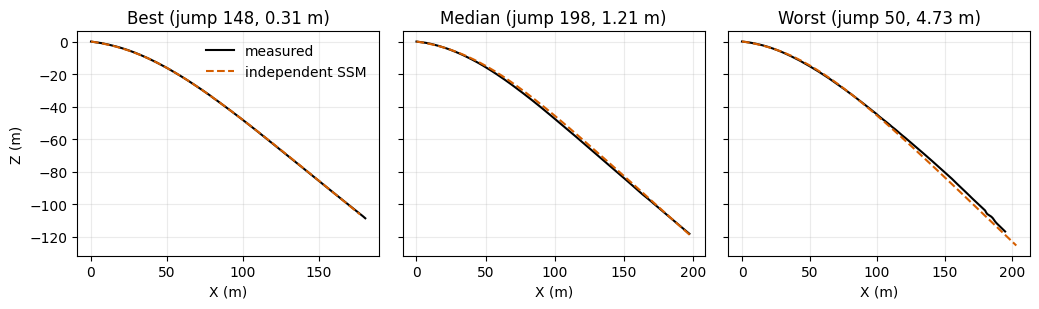

Wrote independent_model_trajectory_examples.pdf


In [10]:
# Plot best, median, and worst held-out primary-model trajectories.
errors = np.asarray(
    [
        record["trajectory_error_actual_start_m"]
        for record in primary_records
    ],
    dtype=float,
)
representative = {
    "best": int(np.argmin(errors)),
    "median": int(np.argsort(errors)[len(errors) // 2]),
    "worst": int(np.argmax(errors)),
}

figure, axes = plt.subplots(1, 3, figsize=(10.5, 3.2), sharey=True)
for axis, (label, index) in zip(
    axes, representative.items(), strict=True
):
    actual = primary_states[index]
    predicted = primary_predictions[index]
    axis.plot(
        actual[:, 0],
        actual[:, 2],
        color="black",
        linewidth=1.5,
        label="measured",
    )
    axis.plot(
        predicted[:, 0],
        predicted[:, 2],
        color="#D55E00",
        linewidth=1.5,
        linestyle="--",
        label="independent SSM",
    )
    axis.set_title(
        f"{label.capitalize()} (jump {index}, {errors[index]:.2f} m)"
    )
    axis.set_xlabel("X (m)")
    axis.grid(alpha=0.25)
axes[0].set_ylabel("Z (m)")
axes[0].legend(frameon=False)
figure.tight_layout()
figure.savefig(OUTPUT_FIGURE, bbox_inches="tight")
plt.show()
print(f"Wrote {OUTPUT_FIGURE.relative_to(ROOT)}")


## Interpretation checklist

Use the executed results above to decide whether this model is worth adding to the article.

1. **Independence is achieved by construction.** The primary state and control name sets have an empty intersection, and the saved matrices have dimensions $A:7\times7$, $B:7\times19$, $C:4\times7$, and $D:4\times19$.
2. **Speed is recursively modeled.** Resultant speed is initialized as a state and predicted thereafter; it is not supplied as a measured control at every time step.
3. **The comparison variants are exploratory.** Selecting whichever variant has the lowest LOOCV error after inspecting all five would make that reported score optimistically biased unless model selection were nested inside another validation loop.
4. **The model remains conditional.** It consumes the full measured posture and wind sequences from the held-out jump. It does not predict a trajectory solely from information available before takeoff.
5. **Stability still matters.** A spectral radius above one rules out unbounded extrapolation even when observed-horizon errors are acceptable.
6. **Timestamp sensitivity is retained.** The no-repair subset result checks whether the repaired timestamps dominate performance.
